<a target="_blank" href="https://colab.research.google.com/github/taobrienlbl/advanced_earth_science_data_analysis/blob/fall_2025_iub/content/lessons/02_modules_vscode_git/02_last_class_refresher.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

# Warmup: fundamentals

Recall that last week's objectives were:

* Describe fundamental aspects of a working Python script
* Implement novel functions and for loops along with appropriate unit tests
* Utilize 'external' python packages

This warm-up aims to build on those objectives and reinforce them.


## 1. Basics of functions

### 1(a): ins and outs

Run the following cell.  It doesn't work as expected.  Explain why (in a markdown cell below it) and create a new cell below that with a fixed version of the code.

In [3]:
def factorial(n):
    """Calculates the factorial of a number."""
    fac = 1
    if n == 1:
        fac = 1
    else:
        fac = n * factorial(n-1)


# test the factorial function; this should print 120
print(factorial(5))

TypeError: unsupported operand type(s) for *: 'int' and 'NoneType'

The code in 1a doesn't print the output and provides an error because it does not use return for the calcualtions. 

In [4]:
# correct code for 1a

def factorial(n):
    """Calculates the factorial of a number."""
    fac = 1
    if n == 1:
        return 1
    else:
        return n * factorial(n-1)


# this prints 120
print(factorial(5))

120


### 1(b): Writing new functions

Write a function representing the formula $z = x^2 + y^2$ and verify that it works as expected.

In [5]:
# code for 1b
def z_function(x,y):
    return x**2 + y**2
xt, yt, zt = [1, 3, 5], [4, 3, 2], [17, 18, 29] 
for x, y, z in zip(xt, yt, zt):
    assert z_function(x, y) == z, "Incorrect result for x{}, y={}".format(x, y)

print("All of the tests worked.")


All of the tests worked.


### 1(c): Scope

We haven't yet discussed the concept of *scope*, so we'll introduce it here through examining an interesting effect (and we'll discuss it more as time goes on.)

Run the cell below.  We see that the value of `a` is redefined when `redefine_and_print_a()` is called, so why does the last print statement contain the original definition of `a` and not the one it was given within the function?


In [6]:
# define a as a global variable here
a = "This is `a` with global scope."
# print a to show its value
print(f"1: {a}")

# define a function
def redefine_and_print_a():
    # define a as a local variable here
    a = "This is `a` with local scope."
    # print a to show its value
    print(f"2: {a}")

# call the function
redefine_and_print_a()

# print a one more time to show its value
print(f"3: {a}")



1: This is `a` with global scope.
2: This is `a` with local scope.
3: This is `a` with global scope.


Guess/answer to 1c here:
Both the variables have the same name, 'a', but they are in different scopes, global and local. The local 'a' variable is within the redefine_and_print_a() function, while the global 'a' variable is within the script. 

## 2. Using external packages

Make a plot of the following equation  using `numpy` and `matplotlib`.  Use `x` values ranging from -8 to 8, and make plots using the following values of $\sigma$: $\sigma = [0.25,0.5,1,2,4]$

$$N(x) = \frac{1}{\sigma \sqrt{2 \pi}} e^{-\frac{x^2}{2 \sigma^2}}$$

Your solution should (a) define a new function to represent this formula, and (b) use a `for` loop.

If you have time, customize the x- and y-axis labels, and add a legend.

In [8]:
?ax.plot

Signature: ax.plot(*args, scalex=True, scaley=True, data=None, **kwargs)
Docstring:
Plot y versus x as lines and/or markers.

Call signatures::

    plot([x], y, [fmt], *, data=None, **kwargs)
    plot([x], y, [fmt], [x2], y2, [fmt2], ..., **kwargs)

The coordinates of the points or line nodes are given by *x*, *y*.

The optional parameter *fmt* is a convenient way for defining basic
formatting like color, marker and linestyle. It's a shortcut string
notation described in the *Notes* section below.

>>> plot(x, y)        # plot x and y using default line style and color
>>> plot(x, y, 'bo')  # plot x and y using blue circle markers
>>> plot(y)           # plot y using x as index array 0..N-1
>>> plot(y, 'r+')     # ditto, but with red plusses

You can use `.Line2D` properties as keyword arguments for more
control on the appearance. Line properties and *fmt* can be mixed.
The following two calls yield identical results:

>>> plot(x, y, 'go--', linewidth=2, markersize=12)
>>> plot(x, y, 

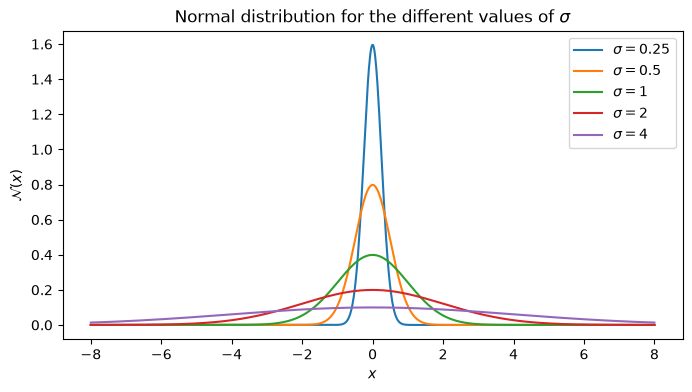

In [9]:
# put your code for 2 here
import numpy as np
import matplotlib.pyplot as plt

def n(x, sigma):
    return np.exp(-x**2 / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi))
sigma_val = [0.25, 0.5, 1, 2, 4]
x = np.linspace(-8,8,1000)

fig, ax = plt.subplots(1, 1, figsize=(8,4))
for sigma in sigma_val:
    
    ax.plot(x, n(x, sigma), label=r"$\sigma={}$".format(sigma))
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$\mathcal{N}(x)$")
#setting the title
ax.set_title(r"Normal distribution for the different values of $\sigma$")
ax.legend()
plt.show()